### define global variables

In [1]:
model_order = [
    "Cohere CAT+",
    "Command A+",
    "CUNI-EdUKate",
    "CUNI-MH-v3",
    "DeepSeek V4 Pro",
    "Dubformer",
    "Gemini 3.1 Pro",
    "Gemma 4 - 4B",
    "Gemma 4 - 31B",
    "GLM 4 - 9B",
    "GoogleTranslate",
    "GPT 5.5",
    "GPT OSS 20B",
    "GPT OSS 120B",
    "Ministral 3 - 14B",
    "Mistral Medium 3.5",
    "Qingqiu-MT-9B",
    "Qwen 3.5 - 9b",
    "Qwen 3.6 - 27b",
    "SalamandraTA",
    "Tiny Aya Global",
    "Tower 9B",
    "TRIVE",
    "UvA-MT",
]

In [2]:
import pandas as pd

# ============================================================
# Import original test set
# ============================================================

rel_testset = pd.read_csv(
    "../df_rel.tsv",
    sep="\t"
)


# ============================================================
# Target-term matches
# ============================================================

rel_matches = pd.read_csv(
    "./wmt_json_translations/results/rel/tgt_term_gold_edited.csv",
    sep=",",
    encoding="utf-8-sig"
)

cols = model_order
rel_matches = rel_matches[cols]

rel_matches_list = rel_matches.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)


# ============================================================
# Distractor matches
# ============================================================

rel_matches_hyponym = pd.read_csv(
    "./wmt_json_translations/results/rel/tgt_term_hyponym_edited.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

rel_matches_cohyponym = pd.read_csv(
    "./wmt_json_translations/results/rel/tgt_term_co-hyponym_edited.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

rel_matches_hypernym = pd.read_csv(
    "./wmt_json_translations/results/rel/tgt_term_hypernym_edited.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]


# ============================================================
# Binarize distractor matches
# ============================================================

rel_matches_hyponym_bin = rel_matches_hyponym.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

rel_matches_cohyponym_bin = rel_matches_cohyponym.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

rel_matches_hypernym_bin = rel_matches_hypernym.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)


# ============================================================
# Cumulative distractor match
#
# 1 = at least one hyponym, co-hyponym, or hypernym match
# 0 = no distractor match
# ============================================================

rel_distractors_matches_list = (
    (
        rel_matches_hypernym_bin
        + rel_matches_cohyponym_bin
        + rel_matches_hyponym_bin
    ) > 0
).astype(int)

In [3]:
#upload training history and save in a variable
import csv
import pandas as pd

results_rel = pd.read_csv("./wmt_json_translations/results/term_accuracy_rates_rel.tsv", sep="\t")
results_rel.columns = results_rel.columns.str.strip()
results_rel["model"] = results_rel["model"].astype(str).str.strip()

# Filter and reorder to match cols
results = results_rel[results_rel["model"].isin(cols)].copy()
results["model"] = pd.Categorical(results["model"], categories=cols, ordered=True)
results = results.sort_values("model").reset_index(drop=True)


# Validate parallel and synthetic contexts performances

In [4]:
def compare_parallel_contexts(rel_testset, rel_matches_list):
    """
    Compare model performance between synthetic and parallel contexts.

    The function identifies paired instance_ids using in the test set, where human parallel
    examples are marked with the `_par` suffix. It then separates synthetic
    and parallel rows, aligns them by their shared base ID, and calculates
    the percentage of positive matches for each model in both sets.

    Parameters
    ----------
    rel_testset : pandas.DataFrame
        Eurac Test set.

    rel_matches_list : pandas.DataFrame
        Table with term matches (derived from term_finder pipeline). Rows are testset instances, columns are models
        Matches are 1, non matches are 0

    Returns
    -------
    pandas.DataFrame
        A table with one row per model and columns:
        `model`, `synthetic`, and `parallel` contexts.
    """

    # Copies
    rel_testset_op = rel_testset.copy()
    rel_matches_list_op = rel_matches_list.copy()

    # Attach IDs to result table, assuming rows are in the same order as rel_testset
    rel_matches_list_op["instance_id"] = rel_testset_op["instance_id"].values

    # Create base ID and parallel flag
    rel_testset_op["base_id"] = rel_testset_op["instance_id"].str.replace(
        r"_par$", "", regex=True
    )
    rel_testset_op["is_par"] = rel_testset_op["instance_id"].str.endswith("_par")

    # Keep only IDs that have both base and _par versions
    paired_base_ids = (
        rel_testset_op
        .groupby("base_id")["is_par"]
        .nunique()
    )

    paired_base_ids = paired_base_ids[paired_base_ids == 2].index

    paired_map = rel_testset_op[
        rel_testset_op["base_id"].isin(paired_base_ids)
    ][["instance_id", "base_id", "is_par"]]

    # Add base_id and is_par to result table
    all_par_results = rel_matches_list_op.merge(
        paired_map,
        on="instance_id",
        how="inner"
    )

    # Identify model columns
    metadata_cols = {"instance_id", "base_id", "is_par"}
    model_cols = [c for c in all_par_results.columns if c not in metadata_cols]

    # Synthetic / non-parallel rows
    non_par_results = (
        all_par_results[all_par_results["is_par"] == False]
        .set_index("base_id")[model_cols]
        .sort_index()
    )

    # Parallel rows
    par_results = (
        all_par_results[all_par_results["is_par"] == True]
        .set_index("base_id")[model_cols]
        .sort_index()
    )

    # Align both tables by shared base_id
    common_ids = non_par_results.index.intersection(par_results.index)

    non_par_aligned = non_par_results.loc[common_ids]
    par_aligned = par_results.loc[common_ids]
    #print(par_aligned)
    
    
    # Percentage of 1s for each model in each table
    final_results = pd.DataFrame({
        "synthetic": non_par_aligned.mean() * 100,
        "parallel": par_aligned.mean() * 100
    })

    # Models as rows
    final_results = final_results.reset_index()
    final_results.columns = ["model", "synthetic", "parallel"]

    return final_results

import matplotlib.pyplot as plt
import numpy as np


def plot_parallel_context_results(results, figsize=(12, 6)):
    """
    Plot synthetic vs. parallel context match success percentages by model.

    Parameters
    ----------
    results : pandas.DataFrame
        Output of compare_parallel_contexts(), with columns:
        'model', 'synthetic', and 'parallel'.

    figsize : tuple, optional
        Figure size.

    Returns
    -------
    fig, ax
        Matplotlib figure and axes objects.
    """

    x = np.arange(len(results))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical line connecting the two scores for each model
    for i in x:
        ax.plot(
            [i, i],
            [results.loc[i, "synthetic"], results.loc[i, "parallel"]],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Synthetic-context points
    ax.scatter(
        x,
        results["synthetic"],
        marker="o",
        color="tab:blue",
        s=70,
        label="Synthetic",
        zorder=2
    )

    # Parallel-context points
    ax.scatter(
        x,
        results["parallel"],
        marker="D",
        color="tab:orange",
        s=70,
        label="Parallel",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(results["model"], rotation=45, ha="right")

    ax.set_ylabel("Match success (%)")
    ax.set_xlabel("Model")
    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    fig.tight_layout()

    return fig, ax

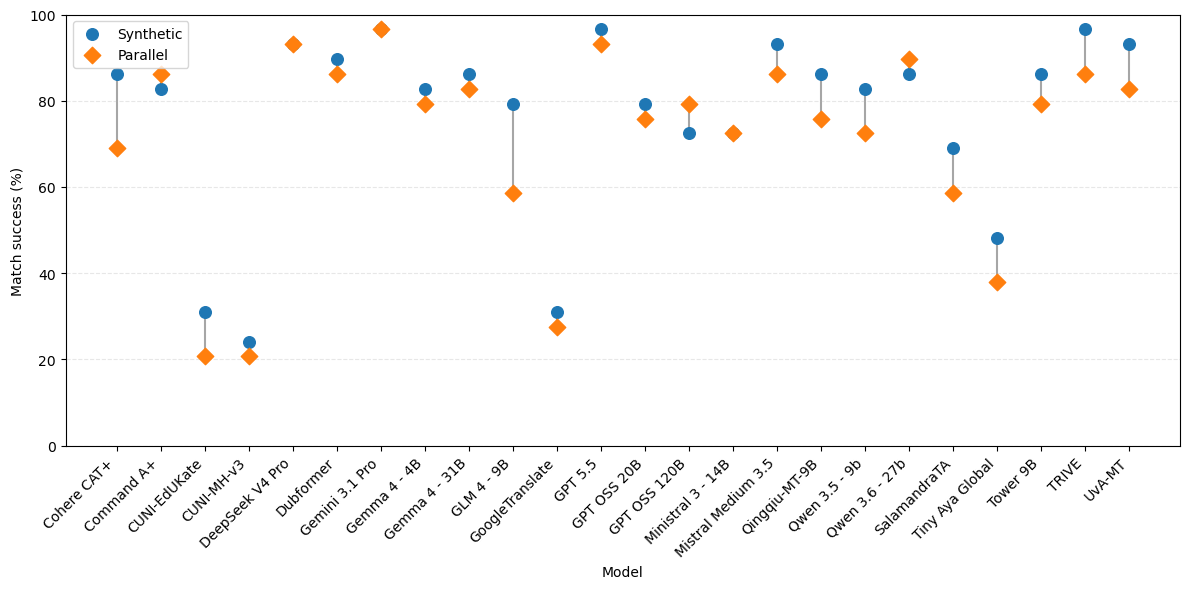

In [5]:
par_synth_results = compare_parallel_contexts(
    rel_testset=rel_testset,
    rel_matches_list=rel_matches_list
)

fig, ax = plot_parallel_context_results(par_synth_results)
#plt.show()

In [6]:
fig.savefig("./results_tables_and_plots/1_synth_validation_ta_rel.png", dpi=300, bbox_inches="tight")
par_synth_results.to_csv("./results_tables_and_plots/1_synth_validation_ta_rel.tsv", sep="\t", index=False)
par_synth_results

,model,synthetic,parallel
0,Cohere CAT+,86.206897,68.965517
1,Command A+,82.758621,86.206897
2,CUNI-EdUKate,31.034483,20.689655
3,CUNI-MH-v3,24.137931,20.689655
4,DeepSeek V4 Pro,93.103448,93.103448
5,Dubformer,89.655172,86.206897
6,Gemini 3.1 Pro,96.551724,96.551724
7,Gemma 4 - 4B,82.758621,79.310345
8,Gemma 4 - 31B,86.206897,82.758621
9,GLM 4 - 9B,79.310345,58.620690


### first result table: comparison of performances btw human and synthetic sources per model

### aggregated results in a table/plot

# Separate par and synth contexts

In [7]:
# Find rows in rel_testset where instance_id ends with "_par"
par_idx = rel_testset.index[
    rel_testset["instance_id"].str.endswith("_par", na=False)
]

# Original rel_testset without _par rows
rel_testset_synth = rel_testset.drop(index=par_idx).copy()

# New dataframe with only _par rows
rel_testset_par = rel_testset.loc[par_idx].copy()

# Apply the same split to other aligned variables
rel_matches_list_par = rel_matches_list.loc[par_idx].copy()
rel_matches_list_synth = rel_matches_list.drop(index=par_idx).copy()

# Apply the same split to distractor matches
rel_distractors_matches_list_par = rel_distractors_matches_list.loc[par_idx].copy()
rel_distractors_matches_list_synth = rel_distractors_matches_list.drop(index=par_idx).copy()


rel_matches_hyponym_synth = rel_matches_hyponym.drop(index=par_idx).copy()
rel_matches_cohyponym_synth = rel_matches_cohyponym.drop(index=par_idx).copy()
rel_matches_hypernym_synth = rel_matches_hypernym.drop(index=par_idx).copy()

In [8]:
rel_testset_synth['variety'].value_counts()

variety
Südtirol    273
DE          122
AT           68
CH           64
Name: count, dtype: int64

# Plot term accuracy, bleu and chrf

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def plot_term_accuracy(rel_matches_list, rel_distractors_matches_list,
                       figsize=(12, 6)):
    """
    Plot cumulative distractor match rate and final term accuracy
    for each model.

    Final term accuracy:
        target match = 1 AND distractor match = 0

    Parameters
    ----------
    rel_matches_list : pandas.DataFrame
        Binary target-term matches.
        Rows are test-set instances and columns are models.

    rel_distractors_matches_list : pandas.DataFrame
        Binary cumulative distractor matches.
        1 = at least one distractor matched
        0 = no distractor matched.

    figsize : tuple, optional
        Figure size.

    Returns
    -------
    fig, ax : matplotlib Figure and Axes

    accuracy_df : pandas.DataFrame
        Table containing model, term accuracy,
        and cumulative distractor match rate.
    """

    # Align rows and models
    common_index = rel_matches_list.index.intersection(
        rel_distractors_matches_list.index
    )

    common_cols = rel_matches_list.columns.intersection(
        rel_distractors_matches_list.columns
    )

    target = rel_matches_list.loc[common_index, common_cols]
    distractor = rel_distractors_matches_list.loc[
        common_index, common_cols
    ]

    # Percentage of examples containing at least one distractor match
    distractor_rate = distractor.mean() * 100

    # Correct target AND no distractor
    term_accuracy = (
        (target == 1) & (distractor == 0)
    ).mean() * 100

    # Results dataframe
    accuracy_df = pd.DataFrame({
        "model": common_cols,
        "term_accuracy": term_accuracy.values,
        "distractor_match_rate": distractor_rate.values
    })

    x = np.arange(len(accuracy_df))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical line connecting both values for every model
    for i in x:
        ax.plot(
            [i, i],
            [
                accuracy_df.loc[i, "distractor_match_rate"],
                accuracy_df.loc[i, "term_accuracy"]
            ],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Term accuracy
    ax.scatter(
        x,
        accuracy_df["term_accuracy"],
        marker="o",
        color="green",
        s=70,
        #label="Term accuracy",
        zorder=2
    )

    # Cumulative distractor match rate
    ax.scatter(
        x,
        accuracy_df["distractor_match_rate"],
        marker="D",
        color="red",
        s=70,
        #label="Cumulative distractor match rate",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        accuracy_df["model"],
        rotation=45,
        ha="right"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("Term Accuracy")
    ax.set_title(
        "Results for REL subset"
    )

    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    fig.tight_layout()

    return fig, ax, accuracy_df

C:\Users\pdinatale\AppData\Local\Temp\ipykernel_15012\344164897.py:122: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


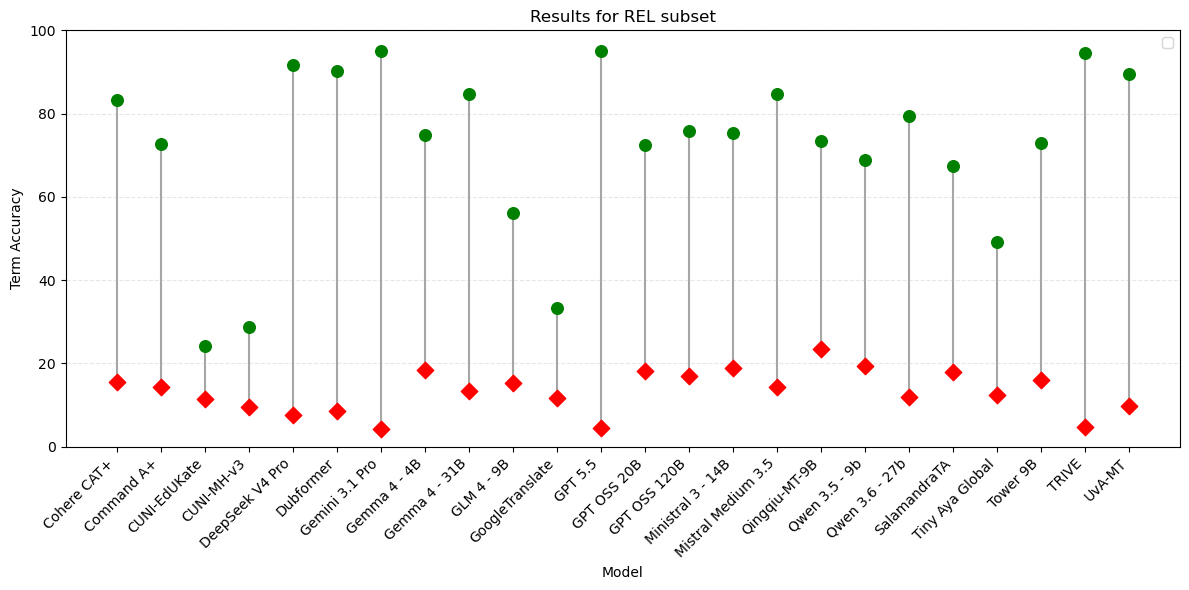

In [10]:
fig, ax, term_accuracy_df = plot_term_accuracy(
    rel_matches_list_synth,
    rel_distractors_matches_list_synth
)

plt.show()

In [11]:
fig.savefig("./results_tables_and_plots/2_ta_rel.png", dpi=300, bbox_inches="tight")

term_accuracy_df

,model,term_accuracy,distractor_match_rate
0,Cohere CAT+,83.301708,15.559772
1,Command A+,72.675522,14.231499
2,CUNI-EdUKate,24.288425,11.385199
3,CUNI-MH-v3,28.842505,9.487666
4,DeepSeek V4 Pro,91.650854,7.590133
5,Dubformer,90.322581,8.538899
6,Gemini 3.1 Pro,95.066414,4.174573
7,Gemma 4 - 4B,74.952562,18.406072
8,Gemma 4 - 31B,84.819734,13.472486
9,GLM 4 - 9B,56.166983,15.370019


# Term accuracy by variety

# are smaller models worse on austrian data?

In [26]:
# Count each individual legal domain without exploding the dataframe
variety_counts = (
    rel_testset_synth["variety"]
    .dropna()
    .str.split("|")
    .apply(lambda x: [d.strip() for d in x])
    .sum()
)

variety_counts = pd.Series(variety_counts).value_counts()

variety_counts

Südtirol    273
DE          122
AT           68
CH           64
Name: count, dtype: int64

In [27]:
def term_accuracy_by_variety(
    rel_testset,
    rel_matches,
    variety_column="variety",
    decimals=2
):
    """
    Create a wide terminology-accuracy table by variety.

    Each distinct variety value is evaluated separately.
    No grouping of values is applied.
    A final Mean row is added across models.
    """

    if len(rel_testset) != len(rel_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(rel_testset)}, "
            f"matches = {len(rel_matches)}"
        )

    results = []

    # Keep every distinct variety value
    variety_values = (
        rel_testset[variety_column]
        .dropna()
        .unique()
    )

    # Sort where possible
    try:
        variety_values = sorted(variety_values)
    except TypeError:
        pass

    for value in variety_values:

        mask = rel_testset[variety_column] == value

        variety_matches = rel_matches.loc[mask]

        variety_accuracy = variety_matches.mean() * 100

        for model, accuracy in variety_accuracy.items():
            results.append({
                "model": model,
                "variety": value,
                "term_accuracy": accuracy
            })

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="variety",
        values="term_accuracy"
    )

    table_df = table_df[variety_values].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    # Mean accuracy across models for each variety
    table_df.loc["Mean"] = (
        table_df.mean(axis=0).round(decimals)
    )

    return table_df

In [28]:
variety_accuracy_table = term_accuracy_by_variety(
    rel_testset=rel_testset_synth,
    rel_matches=rel_matches_list_synth,
    variety_column="variety",
    decimals=2
)

variety_accuracy_table

,AT,CH,DE,Südtirol
CUNI-EdUKate,23.53,17.19,18.03,28.94
CUNI-MH-v3,29.41,25.00,27.05,30.40
Cohere CAT+,82.35,84.38,86.07,82.05
Command A+,64.71,76.56,55.74,81.32
DeepSeek V4 Pro,89.71,93.75,95.08,90.11
Dubformer,92.65,89.06,92.62,89.01
GLM 4 - 9B,47.06,51.56,49.18,62.64
GPT 5.5,95.59,96.88,94.26,94.87
GPT OSS 120B,77.94,78.12,71.31,76.92
GPT OSS 20B,73.53,68.75,73.77,72.53


In [29]:
variety_accuracy_table = variety_accuracy_table[["Südtirol", "DE", "AT", "CH"]]
variety_accuracy_table.rename_axis("model").reset_index().to_csv("./results_tables_and_plots/ta_rel.tsv", sep="\t", index=False)
#variety_accuracy_table.to_csv("./results_tables_and_plots/ta_rel.tsv", sep="\t", index=False)

# plot blue

In [30]:
from sacrebleu.metrics import BLEU, CHRF

In [31]:
#import translations

from pathlib import Path

hypotheses_dir='./wmt_json_translations/translations/rel',

translations_folder_rel = Path(
    "./wmt_json_translations/translations/rel"
)

# Read every .txt file in the folder
translation_columns = {}

for txt_file in sorted(translations_folder_rel.glob("*.txt")):
    model_name = txt_file.stem

    with open(txt_file, "r", encoding="utf-8") as f:
        translations = [line.rstrip("\n") for line in f]

    translation_columns[model_name] = translations


# Check that all models have the same number of translations
lengths = {
    model: len(translations)
    for model, translations in translation_columns.items()
}

if len(set(lengths.values())) != 1:
    raise ValueError(
        f"Translation files have different numbers of rows: {lengths}"
    )


# Create dataframe:
# columns = models
# rows = hypothesis translations
hyp_translations_rel = pd.DataFrame(translation_columns)

hyp_translations_rel_synth = hyp_translations_rel.drop(index=par_idx).copy()

In [32]:
def score_corpus(hypotheses, references, metric='chrf', n_bootstrap=1000):
    """
    Compute corpus-level BLEU or chrF for every model.

    Parameters
    ----------
    hypotheses : str, Path, or pd.DataFrame
        Either:
          - a directory containing one .txt file per model (filename = model name), or
          - a DataFrame with one column per model, one row per segment.
    references : str, Path, or list[str]
        Either:
          - a path to a TSV with a 'context' column holding reference sentences, or
          - a list of reference sentences (one per segment).
    metric : str
        'bleu' or 'chrf'.
    n_bootstrap : int
        Bootstrap resamples for confidence intervals.

    Returns
    -------
    scores : dict[str, float]
        model_name -> corpus score.
    results_df : pd.DataFrame
        New DataFrame with columns ['model', metric], one row per model.
    """
    assert metric in ('bleu', 'chrf'), "metric must be 'bleu' or 'chrf'"

    # --- load reference ---
    if isinstance(references, (list, tuple, pd.Series)):
        references = [str(r) for r in references]
    else:
        reference_path = Path(references)
        if not reference_path.exists():
            raise FileNotFoundError(f"Reference file not found: {reference_path}")

        references_df = pd.read_csv(reference_path, sep='\t', encoding='utf-8')
        if 'context' not in references_df.columns:
            raise ValueError(
                f"Column 'context' not found in {reference_path}. "
                f"Available columns: {list(references_df.columns)}"
            )
        references = references_df['context'].astype(str).tolist()

    # --- init scorer ---
    if metric == 'bleu':
        scorer = BLEU(tokenize='13a')
        decimals = 2
    else:
        scorer = CHRF(word_order=2)
        decimals = 4

    # --- build model_name -> list[str] mapping from either input type ---
    model_hyps = {}

    if isinstance(hypotheses, pd.DataFrame):
        for model_name in hypotheses.columns:
            model_hyps[model_name] = hypotheses[model_name].astype(str).tolist()

    else:
        hypotheses_dir = Path(hypotheses)
        if not hypotheses_dir.is_dir():
            raise NotADirectoryError(f"Hypotheses directory not found: {hypotheses_dir}")

        hypothesis_files = sorted(hypotheses_dir.glob('*.txt'))
        if not hypothesis_files:
            raise FileNotFoundError(f"No .txt files found in: {hypotheses_dir}")

        for hyp_file in hypothesis_files:
            with open(hyp_file, encoding='utf-8') as f:
                model_hyps[hyp_file.stem] = [line.rstrip('\n') for line in f]

    if not model_hyps:
        raise ValueError("No models found in `hypotheses` (empty directory or empty DataFrame).")

    # --- score each model ---
    print(f"{'='*60}\nScoring with {metric.upper()}\n{'='*60}")

    scores = {}
    for model_name, hyps in model_hyps.items():
        if len(hyps) != len(references):
            raise ValueError(
                f"Length mismatch for '{model_name}': "
                f"{len(hyps)} hypotheses vs {len(references)} references"
            )

        result = scorer.corpus_score(hyps, [references], n_bootstrap=n_bootstrap)
        score = round(result.score, decimals)
        scores[model_name] = score

        #print(f"  {model_name}:")
        #print(f"    Result details: {result}")
        #print(f"    Signature:      {scorer.get_signature()}")

    # --- build results DataFrame from scratch ---
    results_df = pd.DataFrame(
        {'model': list(scores.keys()), metric: list(scores.values())}
    )

    return scores, results_df

In [33]:
df_rel = pd.read_csv('../df_rel.tsv', sep='\t', encoding='utf-8')
references = df_rel['reference_context_german'].astype(str).tolist()

references_par = [references[i] for i in par_idx]
references_synth = [r for i, r in enumerate(references) if i not in set(par_idx)]

In [34]:
#filter references by language variety
def filter_references_by_variety(
    references,
    testset,
    variety_value,
    variety_column="variety"
):
    if len(references) != len(testset):
        raise ValueError(
            f"Length mismatch: references = {len(references)}, "
            f"test set = {len(testset)}"
        )

    valid_varieties = {"Südtirol", "DE", "AT", "CH"}

    if variety_value not in valid_varieties:
        raise ValueError(
            f"Unknown variety '{variety_value}'. "
            f"Expected one of: {sorted(valid_varieties)}"
        )

    mask = (
        testset[variety_column]
        .reset_index(drop=True)
        == variety_value
    )

    filtered_references = (
        pd.Series(references)
        .reset_index(drop=True)
        .loc[mask]
        .tolist()
    )

    print(f"Original references: {len(references)}")
    print(f"{variety_value} references: {len(filtered_references)}")

    return filtered_references

def filter_hypotheses_by_variety(
    hypotheses,
    testset,
    variety_value,
    variety_column="variety"
):
    if len(hypotheses) != len(testset):
        raise ValueError(
            f"Length mismatch: hypotheses = {len(hypotheses)}, "
            f"test set = {len(testset)}"
        )

    mask = (
        testset[variety_column]
        .reset_index(drop=True)
        == variety_value
    )

    filtered_hypotheses = (
        hypotheses
        .reset_index(drop=True)
        .loc[mask]
        .reset_index(drop=True)
    )

    print(f"Original hypotheses: {len(hypotheses)}")
    print(f"{variety_value} hypotheses: {len(filtered_hypotheses)}")

    return filtered_hypotheses

In [35]:
references_suedtirol = filter_references_by_variety(
    references_synth,
    rel_testset_synth,
    "Südtirol"
)

references_de = filter_references_by_variety(
    references_synth,
    rel_testset_synth,
    "DE"
)

references_at = filter_references_by_variety(
    references_synth,
    rel_testset_synth,
    "AT"
)

references_ch = filter_references_by_variety(
    references_synth,
    rel_testset_synth,
    "CH"
)


hyp_suedtirol = filter_hypotheses_by_variety(
    hyp_translations_rel_synth,
    rel_testset_synth,
    "Südtirol"
)

hyp_de = filter_hypotheses_by_variety(
    hyp_translations_rel_synth,
    rel_testset_synth,
    "DE"
)

hyp_at = filter_hypotheses_by_variety(
    hyp_translations_rel_synth,
    rel_testset_synth,
    "AT"
)

hyp_ch = filter_hypotheses_by_variety(
    hyp_translations_rel_synth,
    rel_testset_synth,
    "CH"
)

Original references: 527
Südtirol references: 273
Original references: 527
DE references: 122
Original references: 527
AT references: 68
Original references: 527
CH references: 64
Original hypotheses: 527
Südtirol hypotheses: 273
Original hypotheses: 527
DE hypotheses: 122
Original hypotheses: 527
AT hypotheses: 68
Original hypotheses: 527
CH hypotheses: 64


In [36]:
# Südtirol
_, bleu_suedtirol_df = score_corpus(
    hypotheses=hyp_suedtirol,
    references=references_suedtirol,
    metric="bleu"
)

# Germany
_, bleu_de_df = score_corpus(
    hypotheses=hyp_de,
    references=references_de,
    metric="bleu"
)

# Austria
_, bleu_at_df = score_corpus(
    hypotheses=hyp_at,
    references=references_at,
    metric="bleu"
)

# Switzerland
_, bleu_ch_df = score_corpus(
    hypotheses=hyp_ch,
    references=references_ch,
    metric="bleu"
)


# Rename BLEU columns
bleu_suedtirol_df = bleu_suedtirol_df.rename(
    columns={"bleu": "ST"}
)

bleu_de_df = bleu_de_df.rename(
    columns={"bleu": "DE"}
)

bleu_at_df = bleu_at_df.rename(
    columns={"bleu": "AT"}
)

bleu_ch_df = bleu_ch_df.rename(
    columns={"bleu": "CH"}
)


# Merge into one dataframe
bleu_by_variety_df = (
    bleu_suedtirol_df
    .merge(bleu_de_df, on="model")
    .merge(bleu_at_df, on="model")
    .merge(bleu_ch_df, on="model")
)

bleu_by_variety_df

Scoring with BLEU
Scoring with BLEU
Scoring with BLEU
Scoring with BLEU


,model,ST,DE,AT,CH
0,Cohere CAT+,39.14,36.72,40.17,41.01
1,Command A+,38.83,30.57,36.48,34.52
2,CUNI-EdUKate,30.84,27.25,28.34,29.65
3,CUNI-MH-v3,31.69,30.22,28.97,30.47
4,DeepSeek V4 Pro,46.97,44.92,48.46,47.64
5,Dubformer,46.23,43.95,46.13,46.06
6,Gemini 3.1 Pro,53.19,51.82,54.19,54.12
7,Gemma 4 - 31B,42.76,39.44,41.74,43.65
8,Gemma 4 - 4B,35.17,30.56,32.09,34.90
9,GLM 4 - 9B,28.25,23.90,25.39,28.27


In [42]:
bleu_by_variety_df.to_csv("./results_tables_and_plots/bleu_rel.tsv", sep="\t", index=False)


# Analysis by distractor type 

In [38]:
import pandas as pd
import numpy as np


def match_rate_distractor_rel(matches_df):
    """
    Calculate match rate (%) for each model.

    Rules
    -----
    []                  -> 0
    non-empty term/list -> 1
    None / NaN / ""     -> excluded

    Returns
    -------
    pandas.DataFrame
        One row per model with:
        model, match_rate, n_evaluated, n_matches
    """

    results = []

    for model in matches_df.columns:

        col = matches_df[model]

        # Exclude actual NaN / None and empty strings
        valid_mask = (
            col.notna()
            & (col.astype(str).str.strip() != "")
            & (col.astype(str).str.strip().str.lower() != "nan")
        )

        valid = col.loc[valid_mask]

        # [] = 0, anything else = 1
        binary = valid.apply(
            lambda x: 0 if str(x).strip() == "[]" else 1
        )

        results.append({
            "model": model,
            "match_rate": binary.mean() * 100,
            "n_evaluated": len(binary),
            "n_matches": binary.sum()
        })

    return pd.DataFrame(results)

In [39]:
rel_cohyponym_accuracy = match_rate_distractor_rel(
    rel_matches_cohyponym_synth
)

rel_hyponym_accuracy = match_rate_distractor_rel(
    rel_matches_hyponym_synth
)

rel_hypernym_accuracy = match_rate_distractor_rel(
    rel_matches_hypernym_synth
)

rel_distractor_rates = (
    rel_hyponym_accuracy[["model", "match_rate"]]
    .rename(columns={"match_rate": "hyponym_rate"})
    .merge(
        rel_cohyponym_accuracy[["model", "match_rate"]]
        .rename(columns={"match_rate": "cohyponym_rate"}),
        on="model"
    )
    .merge(
        rel_hypernym_accuracy[["model", "match_rate"]]
        .rename(columns={"match_rate": "hypernym_rate"}),
        on="model"
    )
)

mean_row = {
    "model": "Mean",
    "hyponym_rate": rel_distractor_rates["hyponym_rate"].mean(),
    "cohyponym_rate": rel_distractor_rates["cohyponym_rate"].mean(),
    "hypernym_rate": rel_distractor_rates["hypernym_rate"].mean()
}

rel_distractor_rates = pd.concat(
    [rel_distractor_rates, pd.DataFrame([mean_row])],
    ignore_index=True
)

rel_distractor_rates

,model,hyponym_rate,cohyponym_rate,hypernym_rate
0,Cohere CAT+,23.026316,8.219178,9.510086
1,Command A+,15.131579,6.849315,10.951009
2,CUNI-EdUKate,3.289474,2.739726,14.409222
3,CUNI-MH-v3,2.631579,2.739726,11.527378
4,DeepSeek V4 Pro,12.500000,2.739726,4.899135
5,Dubformer,13.157895,4.566210,4.610951
6,Gemini 3.1 Pro,5.263158,2.739726,2.881844
7,Gemma 4 - 4B,17.105263,10.045662,14.697406
8,Gemma 4 - 31B,15.789474,7.762557,9.510086
9,GLM 4 - 9B,8.552632,7.762557,14.985591


In [43]:
rel_distractor_rates.to_csv("./results_tables_and_plots/3_distractor_rel.tsv", sep="\t", index=False)


###  for var subset you can directly use the tsv of results. For rel and hom, it depends on data visualization. For variety-invariant results, yes. otherwise, attach result of the matcher and the testset, then groupby variety. 
### Bleu

### display in a plot the results of the correct term selection together with the bleu

### repeat for the main results of each subset (call the function on the subset data every time)

# Analysis by distractor number

In [58]:
# distractors do not impact this challenge

In [20]:
dist_counts = (
    rel_testset_synth["n_distractors"]
    .value_counts(dropna=False)
    .sort_index()
)

dist_counts

n_distractors
1     176
2     134
3      76
4      50
5      27
6      24
7      16
8       7
9       2
10      6
12      4
15      2
16      2
18      1
Name: count, dtype: int64

In [21]:
def term_accuracy_by_distractor_count(
    rel_testset,
    rel_matches,
    distractor_column="N distractor",
    decimals=2
):
    """
    Create a wide terminology-accuracy table by number of distractors.

    Values 4 and above are grouped into a single "4+" category.
    A final Mean row is added across models.
    """

    if len(rel_testset) != len(rel_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(rel_testset)}, "
            f"matches = {len(rel_matches)}"
        )

    # Create grouped distractor categories
    distractor_groups = rel_testset[distractor_column].apply(
        lambda x: "5+" if pd.notna(x) and x >= 5 else x
    )

    results = []

    # Keep numeric groups in order, then 4+
    group_values = sorted(
        [x for x in distractor_groups.dropna().unique() if x != "5+"]
    )

    if "5+" in distractor_groups.values:
        group_values.append("5+")

    for value in group_values:

        mask = distractor_groups == value

        group_matches = rel_matches.loc[mask]

        group_accuracy = group_matches.mean() * 100

        for model, accuracy in group_accuracy.items():
            results.append({
                "model": model,
                "n_distractors": value,
                "term_accuracy": accuracy
            })

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="n_distractors",
        values="term_accuracy"
    )

    table_df = table_df[group_values].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    # Add mean across models for each distractor group
    table_df.loc["Mean"] = table_df.mean(axis=0).round(decimals)

    return table_df

In [22]:
distractor_accuracy_table = term_accuracy_by_distractor_count(
    rel_testset=rel_testset_synth,
    rel_matches=rel_matches_list_synth,
    distractor_column="n_distractors",  # change if your exact column name differs
    decimals=2
)

distractor_accuracy_table

,1,2,3,4,5+
CUNI-EdUKate,23.30,27.61,26.32,18.00,23.08
CUNI-MH-v3,29.55,29.10,32.89,26.00,25.27
Cohere CAT+,88.64,79.10,86.84,78.00,79.12
Command A+,72.16,72.39,82.89,80.00,61.54
DeepSeek V4 Pro,92.05,92.54,94.74,92.00,86.81
Dubformer,90.91,91.04,89.47,96.00,85.71
GLM 4 - 9B,64.77,57.46,53.95,44.00,46.15
GPT 5.5,94.32,97.01,93.42,98.00,93.41
GPT OSS 120B,78.41,75.37,78.95,74.00,70.33
GPT OSS 20B,77.84,75.37,71.05,66.00,62.64


In [23]:
distractor_accuracy_table = distractor_accuracy_table.loc[model_order + ["Mean"]].rename_axis("model")
distractor_accuracy_table.to_csv("./results_tables_and_plots/5_distractor_number_rel.tsv", sep="\t", index=True)